# Logistic Regression with Python - Case Study

For this case study we will work with the [Titanic Data Set from Kaggle](https://www.kaggle.com/c/titanic). This is a very famous dataset and very often adopted for students' first step in machine learning! 

We'll be trying to predict a classification - survival or deceased - by implementing Logistic Regression in Python.

We'll use a "semi-cleaned" version of the titanic dataset; if you use the data set directly hosted on Kaggle, you may need to perform some additional data cleaning operations not shown in this lecture notebook.

## Import  Data Analysis and Visualization Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## Import Dataset

In [2]:
data = pd.read_csv('titanic.csv', index_col="PassengerID")
data.head()

,Survived,Pass. Class,Name,Age,Nr Siblings/Spouses,Nr Parents/Children,Ticket,Fare,Cabin,Sex,Embarked - Queenstown,Embarked - Southampton
PassengerID,,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,1,0,1
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,0,0,0
3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,0,0,1
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,0,0,1
5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,NaN,1,0,1


![alt text](titanic_route.png "Title")

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Survived                891 non-null    int64  
 1   Pass. Class             891 non-null    int64  
 2   Name                    891 non-null    object 
 3   Age                     714 non-null    float64
 4   Nr Siblings/Spouses     891 non-null    int64  
 5   Nr Parents/Children     891 non-null    int64  
 6   Ticket                  891 non-null    object 
 7   Fare                    891 non-null    float64
 8   Cabin                   204 non-null    object 
 9   Sex                     891 non-null    int64  
 10  Embarked - Queenstown   891 non-null    int64  
 11  Embarked - Southampton  891 non-null    int64  
dtypes: float64(2), int64(7), object(3)
memory usage: 90.5+ KB


# Exploratory Data Analysis

### TO DO: Visualize data. Which passenger class has most survivors

## Missing Data

We can use seaborn to create a simple heatmap to see where are missing data.

<Axes: ylabel='PassengerID'>

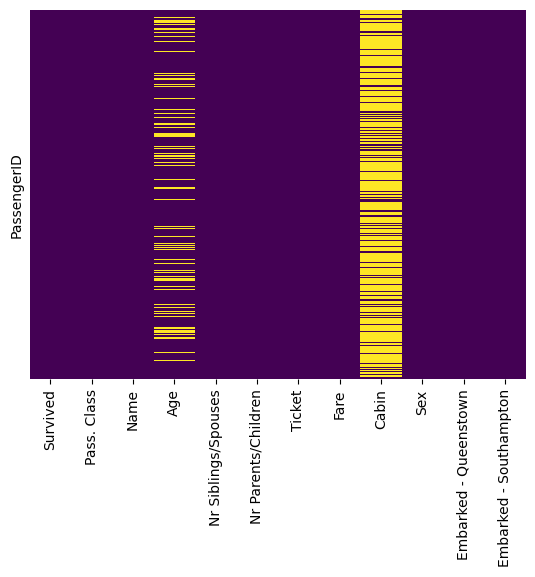

In [4]:
sns.heatmap(data.isnull(), yticklabels=False, cbar=False, cmap='viridis')

<Axes: xlabel='Survived', ylabel='count'>

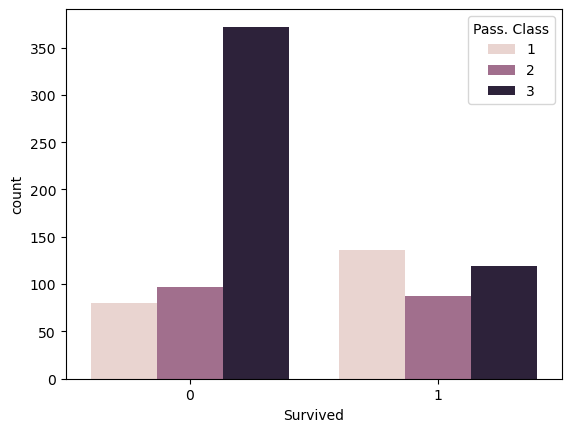

In [5]:
# sns.countplot(x='Survived', hue='Sex', data=data)
sns.countplot(x='Survived', hue='Pass. Class', data=data)

## Missing Data
If data is missing, we cannot use the entire dataset for training. We have to choose:
1. Fill the missing data artificially
2. Discard the missing data

### TO DO: Visualize the missing data and prepare the dataset for training
Hint: Generate artificial values when the missing data can be estimated and when it is not frequent

<Axes: xlabel='Pass. Class', ylabel='Age'>

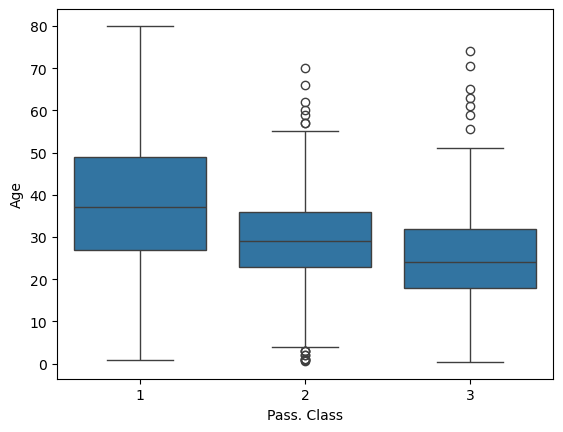

In [6]:
sns.boxplot(x='Pass. Class', y='Age', data=data)

In [7]:
print(data.groupby('Pass. Class')['Age'].median())

Pass. Class
1    37.0
2    29.0
3    24.0
Name: Age, dtype: float64


In [8]:
def impute_age(cols):
    Age = cols[0]
    Pclass = cols[1]
    
    if pd.isnull(Age):
        if Pclass == 1:
            return 37
        elif Pclass == 2:
            return 29
        else:
            return 24
    else:
        return Age

C:\Users\fepor\AppData\Local\Temp\ipykernel_22144\2216940440.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Age = cols[0]
C:\Users\fepor\AppData\Local\Temp\ipykernel_22144\2216940440.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Pclass = cols[1]


<Axes: ylabel='PassengerID'>

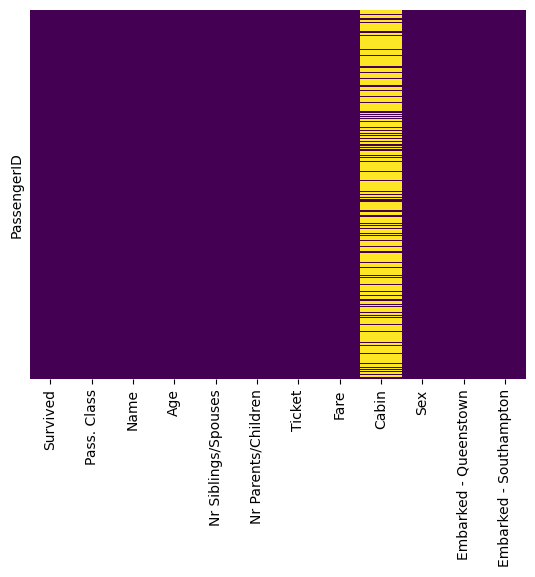

In [9]:
data['Age'] = data[['Age', 'Pass. Class']].apply(impute_age, axis=1)
sns.heatmap(data.isnull(), yticklabels=False, cbar=False, cmap='viridis')

## Managing Cabin column

In [10]:
data.drop(['Cabin', 'Name', 'Ticket'], axis=1, inplace=True)

In [11]:
data.head()

,Survived,Pass. Class,Age,Nr Siblings/Spouses,Nr Parents/Children,Fare,Sex,Embarked - Queenstown,Embarked - Southampton
PassengerID,,,,,,,,,
1,0,3,22.0,1,0,7.2500,1,0,1
2,1,1,38.0,1,0,71.2833,0,0,0
3,1,3,26.0,0,0,7.9250,0,0,1
4,1,1,35.0,1,0,53.1000,0,0,1
5,0,3,35.0,0,0,8.0500,1,0,1


# Building a Logistic Regression model

Let's start by splitting our data into a training set and test set as we did in the linear regression case study.

In [12]:
from sklearn.model_selection import train_test_split
X = data.drop('Survived', axis=1)
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=101)

### TO DO: Train a logistic regression model and use it on the test set

In [13]:
from sklearn.linear_model import LogisticRegression
logmodel = LogisticRegression()
logmodel.fit(X_train, y_train)

c:\Users\fepor\anaconda3\envs\XAI_env\lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

## Performance Evaluation

Confusion Matrix:

\begin{array}{ccc}
& \text{Observed values} &\\
\text{Predicted values} &
\begin{bmatrix}
    TN & FP \\
    FN & TP \\
\end{bmatrix} &
\end{array}


 
<br>

- **TP (True Positive):** Model predicts *positive* and it’s actually *positive*  
- **FP (False Positive):** Model predicts *positive* but it’s actually *negative*  (*false alarm*)  
- **TN (True Negative):** Model predicts *negative* and it’s actually *negative*   
- **FN (False Negative):** Model predicts *negative* but it’s actually *positive*  (*missed detection*) 

F1-score (harmonic mean of precision and recall):
$$
F1 = \frac{2 \times precision \times recall}{precision + recall}
$$
where:
- precision: $\frac{TP}{TP+FP}$ ratio of true positive (real survivors) over all predicted positive (all predicted as survivors, even if some are not) Precision measures the proportion of positive predictions that were actually correct
- recall: $\frac{TP}{TP+FN}$ ratio of true positive (real survivors) over all that should have been predicted as survivors (all predicted as survivors, even if some are not) Recall measures the proportion of actual positives that were correctly identified.

### TO DO: Evaluate the performance of the model

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
predictions = logmodel.predict(X_test)
predictions[:10]

array([0, 1, 1, 0, 0, 0, 0, 0, 1, 1], dtype=int64)

[[133  21]
 [ 38  76]]


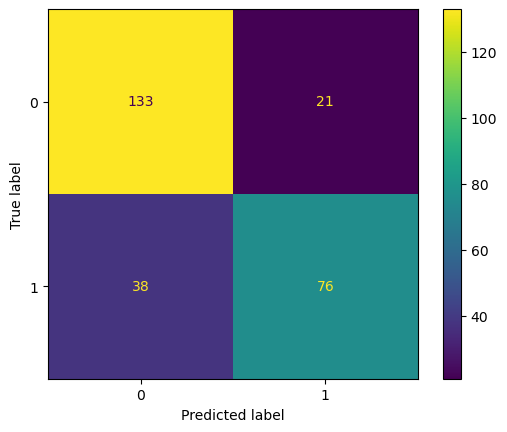

In [15]:
conf_mat = confusion_matrix(y_test, predictions)
print(conf_mat)

matrix = ConfusionMatrixDisplay(conf_mat).plot(values_format=".0f")
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

In [16]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.78      0.86      0.82       154
           1       0.78      0.67      0.72       114

    accuracy                           0.78       268
   macro avg       0.78      0.77      0.77       268
weighted avg       0.78      0.78      0.78       268



Not so bad! You might want to explore other features and the full Titanic Kaggle dataset; some suggestions for feature selection:

* Try grabbing the Title (Dr., Mr., Mrs, etc..) from the name as a feature
* Maybe Ticket information could be exploited

Notice that, when dealing with non-numeric features, it is suggested to convert them into numerical values.

## Improving the model: non-numerical features

In [18]:
# Load original dataset
data = pd.read_csv('titanic.csv', index_col="PassengerID")                               # Import dataset
data.head()

,Survived,Pass. Class,Name,Age,Nr Siblings/Spouses,Nr Parents/Children,Ticket,Fare,Cabin,Sex,Embarked - Queenstown,Embarked - Southampton
PassengerID,,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,1,0,1
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,0,0,0
3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,0,0,1
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,0,0,1
5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,NaN,1,0,1


### From non-numerical to numerical features
Regression models use numerical features to estimate an output. Categorical data can be converted to numerical data through one-hot encoding, that is, a binary vector where the value of 1 represents the active category.

**Example**

Title = {'Mr.', 'Mrs.', 'Miss'}

$$
\begin{bmatrix}
1 \\ 0 \\ 0
\end{bmatrix} \longrightarrow \mathrm{Mr.}
\qquad \qquad
\begin{bmatrix}
0 \\ 1 \\ 0
\end{bmatrix} \longrightarrow \mathrm{Mrs.}
\qquad \qquad
\begin{bmatrix}
0 \\ 0 \\ 1
\end{bmatrix} \longrightarrow \mathrm{Miss}
$$

### TO DO: Convert the "Ticket" and "Title" information into numerical values
- Hint 1 [see below]: How to extract the Title from the name
- Hint 2 [see below]: Group together different titles to simplify the model
- Hint 3 [see below]: Tickets can be distinguished based on the first letter of their name

In [21]:
print(data['Name'].values[0])

# We extract from 'Name' a sequence of letters (A-Za-z) of any length (+) that ends with a dot (\.)
data['Title'] = data['Name'].str.extract('([A-Za-z]+)\.')
# data.head()

Braund, Mr. Owen Harris


['Mr' 'Mrs' 'Miss' 'Master' 'Don' 'Rev' 'Dr' 'Mme' 'Ms' 'Major' 'Lady'
 'Sir' 'Mlle' 'Col' 'Capt' 'Countess' 'Jonkheer']


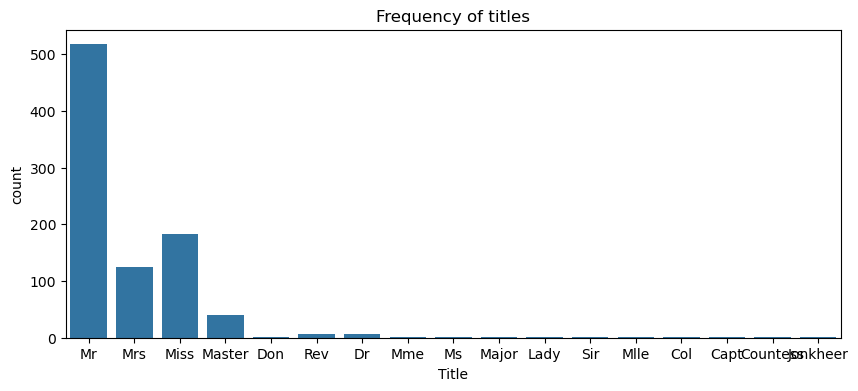

In [27]:
print(data['Title'].unique()) 

plt.figure(figsize=(10, 4))
sns.countplot(data=data, x='Title')
plt.title('Frequency of titles')
plt.show()

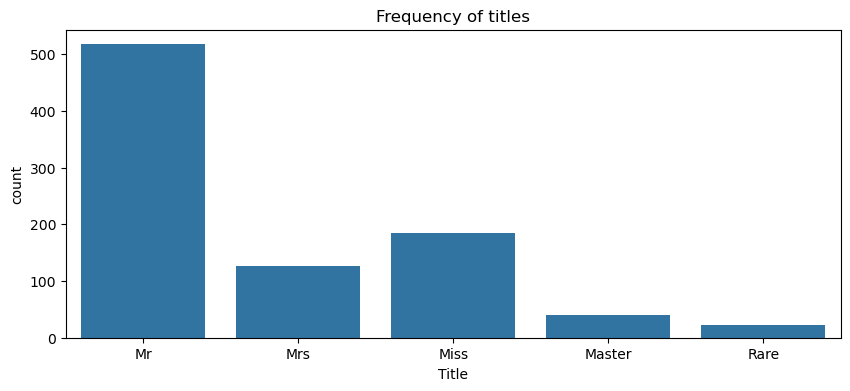

In [28]:
# We group together different classes
data['Title'] = data['Title'].replace('Mme', 'Mrs')
data['Title'] = data['Title'].replace(['Mlle', 'Ms'], 'Miss')
data['Title'] = data['Title'].replace(['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')

plt.figure(figsize=(10, 4))
sns.countplot(data=data, x='Title')
plt.title('Frequency of titles')
plt.show()

In [31]:
# We want to extract the first letter of the Ticket (given information)
data['Ticket_prefix'] = data['Ticket'].apply(lambda x: x.split()[0] if not x.isdigit() else 'No_prefix')
data['Ticket_prefix'][:5]

# def split_if_not_digit(x):
#     if not x.isdigit():
#         return x.split()[0]
#     return 'No_prefix'

# lambda x: x.split()[0] if not x.isdigit() else 'No_prefix'

PassengerID
1          A/5
2           PC
3     STON/O2.
4    No_prefix
5    No_prefix
Name: Ticket_prefix, dtype: object

In [32]:
data = pd.get_dummies(data, columns=['Ticket_prefix'], drop_first=True)
data = pd.get_dummies(data, columns=['Title'], drop_first=True)
data.head() 

,Survived,Pass. Class,Name,Age,Nr Siblings/Spouses,Nr Parents/Children,Ticket,Fare,Cabin,Sex,...,Ticket_prefix_STON/O2.,Ticket_prefix_SW/PP,Ticket_prefix_W./C.,Ticket_prefix_W.E.P.,Ticket_prefix_W/C,Ticket_prefix_WE/P,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
PassengerID,,,,,,,,,,,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,1,...,False,False,False,False,False,False,False,True,False,False
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,0,...,False,False,False,False,False,False,False,False,True,False
3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,0,...,True,False,False,False,False,False,True,False,False,False
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,0,...,False,False,False,False,False,False,False,False,True,False
5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,NaN,1,...,False,False,False,False,False,False,False,True,False,False


## Re-train

Drop original 'Name' and 'Ticket' columns as we've extracted relevant info and estimate age as before

In [33]:
data.drop(['Name', 'Ticket', 'Cabin'], axis=1, inplace=True)
data['Age'] = data[['Age','Pass. Class']].apply(impute_age, axis=1)

C:\Users\fepor\AppData\Local\Temp\ipykernel_22144\2216940440.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Age = cols[0]
C:\Users\fepor\AppData\Local\Temp\ipykernel_22144\2216940440.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Pclass = cols[1]


Train-test split with new features, train new model, and evaluate performance

In [34]:
# Data splitting
X = data.drop('Survived', axis=1)
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=101)

# Train model
logmodel = LogisticRegression(max_iter=1000)
logmodel.fit(X_train, y_train)

# Predict
predictions = logmodel.predict(X_test)

# Performance
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.80      0.90      0.85       154
           1       0.84      0.70      0.77       114

    accuracy                           0.82       268
   macro avg       0.82      0.80      0.81       268
weighted avg       0.82      0.82      0.81       268



AS WE CAN SEE WE GOT AN IMPROVEMENT!!!

## Predictive Imputation
Instead of estimating the age with the median value, why don't we train a regression model?

In [35]:
# Import original dataset and keep only rows relevant for age prediction
data = pd.read_csv('titanic.csv', index_col="PassengerID")
age_df = data[['Age', 'Pass. Class', 'Nr Siblings/Spouses', 'Nr Parents/Children', 'Fare']]

### TO DO: Build a linear regression model to estimate the missing age

In [ ]:
# Data splitting
age_notnull = age_df[age_df['Age'].notnull()] 
age_null = age_df[age_df['Age'].isnull()] 

In [37]:
# Data splitting
X_age_train = age_notnull.drop('Age', axis=1)
y_age_train = age_notnull['Age']

# Not really a test data
X_age_test = age_null.drop('Age', axis=1)

In [38]:
from sklearn.linear_model import LinearRegression

linreg = LinearRegression()
linreg.fit(X_age_train, y_age_train)

predicted_ages = linreg.predict(X_age_test) 
data.loc[data['Age'].isnull(), 'Age'] = predicted_ages 

Perform logistic regression training as before

In [39]:
# Remove non-numerical values
data.drop(['Name', 'Ticket', 'Cabin'], axis=1, inplace=True)

# Train-test split
X = data.drop('Survived', axis=1)
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=101)

# Train model
logmodel = LogisticRegression(max_iter=1000)
logmodel.fit(X_train, y_train)

# Predict and evaluate
predictions = logmodel.predict(X_test)
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.78      0.88      0.83       154
           1       0.80      0.68      0.73       114

    accuracy                           0.79       268
   macro avg       0.79      0.78      0.78       268
weighted avg       0.79      0.79      0.79       268



We got a little improvement

You can try to combine the linear regression imputation and the non-numerical features